# Utilities

## Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import re, string, Levenshtein, joblib
import numpy as np

from collections import Counter

# Natural language processing
import nltk
from nltk.tokenize import word_tokenize
nltk.download('punkt_tab')
# nltk.download('punkt')
from nltk.stem import WordNetLemmatizer
nltk.download('wordnet')
lemmatizer = WordNetLemmatizer()
from nltk.corpus import stopwords
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

# Data science
from sklearn.feature_extraction.text import TfidfVectorizer

# Visualization
from wordcloud import WordCloud

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Pablo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Pablo\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Pablo\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## Functions

In [2]:
# For index_terms treatment, list_flatten and dict_flatten are defined.

def list_flatten(my_list):

    result = []

    # Iterate over my_list
    for element in my_list:

        # If it is a list, unpack and append to result
        if isinstance(element, list):
            result.extend(list_flatten(element))

        # If it is a string
        elif isinstance(element, str):
            element = element.strip() # Remove start/end spaces
            result.append(element)    # Append to result
        
        # Else raise error
        else:
            raise TypeError('Element is not list or string.')

    return result

def dict_flatten(my_dict):
    
    result = []

    # Iterate over my_dict
    for key, val in my_dict.items():

        # If it is a dictionary, unpack and append to result
        if isinstance(val, dict):
            result.extend(dict_flatten(val))
        
        # If it is a list, unpack and append to result
        elif isinstance(val, list):
            result.extend(val)        
        
        # Else raise error
        else:
            raise TypeError('Element is not dictionary or list')
    
    return result

# Text preprocessing
def preprocess_text(text, words2remove):
    text = text.lower()                                                  # Lower case
    text = re.sub(r'[^a-z\s]', ' ', text)                                # Remove numbers and special characteres
    # split(r'\s+') is the same as word_tokenize()
    # if the text doesn´t have special characters
    # text = text.split(r'\s+')                                          # Remove multiple spaces, convert to list
    tokens = word_tokenize(text)                                         # Tokenization
    tokens = [word for word in tokens if word not in stop_words]         # Remove stopwords
    tokens = [word for word in tokens if word not in string.punctuation] # Remove punctuation
    tokens = [word for word in tokens if word not in words2remove]       # Remove words from custom list
    tokens = [lemmatizer.lemmatize(word) for word in tokens]             # Lemmatization
    return ' '.join(tokens)

# Word clouds for given string
def word_cloud(text):
    w = 10
    h = 5
    word_freq = Counter(text.split(' '))
    wordcloud = WordCloud(width=w * 100, height=h * 100,
                           background_color='white',
                           stopwords=None,
                           min_font_size=10).generate_from_frequencies(word_freq)
    plt.figure(figsize=(w, h), facecolor=None)
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.tight_layout(pad=0)
    plt.show()

# Data formatting

In [3]:
# Load data
data = pd.read_csv('../data/input/api/data.csv')
display(data.shape)
display(data.head())

(6724, 6)

,citing_patent_count,title,index_terms,insert_date,abstract,citing_paper_count
0,0,$\beta$-Ga2O3 in Power Electronics Converters:...,"{'ieee_terms': {'terms': ['Schottky diodes', '...",20240410,"In this work, the possibility of using differe...",7
1,0,(2N+1) Selective Harmonic Elimination-PWM for ...,"{'ieee_terms': {'terms': ['Switches', 'Harmoni...",20170209,The performance of modular multilevel converte...,75
2,0,1-MW Full-Bridge MMC for High-Current Low-Volt...,{'dynamic_index_terms': {'terms': ['Low Voltag...,20200826,A full-bridge modular multilevel converter (MM...,0
3,0,1-kV Input 1-MHz GaN Modular Multilevel LLC Co...,"{'ieee_terms': {'terms': ['Silicon carbide', '...",20190527,A modular multilevel LLC converter suitable fo...,3
4,0,"1.5-kV, 1.5-kW, High Voltage Ratio, Bidirectio...",{'ieee_terms': {'terms': ['Multilevel converte...,20250210,Modular multilevel GaN-based isolated DC/DC co...,0


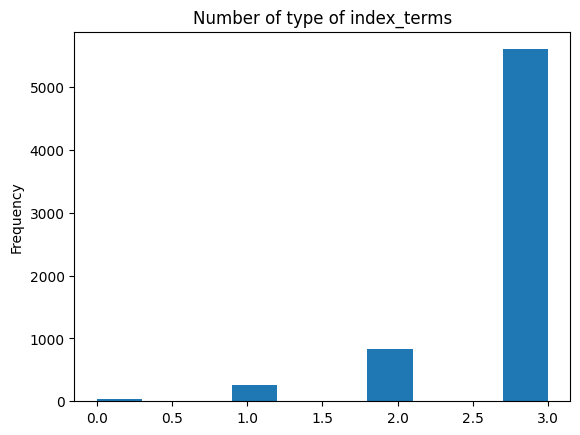

In [4]:
# Count number of type of index_terms
list_terms = [len(eval(dic_index_term).keys()) for dic_index_term in data['index_terms'].values]

plt.figure()
plt.hist(list_terms)
plt.title('Number of type of index_terms')
plt.ylabel('Frequency')
plt.show()

In [5]:
# Sample index_terms value
sample = data.iloc[0]['index_terms']

In [6]:
# The solution is to append all terms to a flat list
dic_terms = eval(sample)
dic_terms

{'ieee_terms': {'terms': ['Schottky diodes',
   'Costs',
   'Performance evaluation',
   'Diamonds',
   'Silicon carbide',
   'Power electronics',
   'Thermal conductivity']},
 'author_terms': {'terms': ['  $\\beta$  -Ga  $_2$  0  $_3$  ',
   'diamond',
   'gallium oxide',
   'HVDC converters',
   'ultra-wide-bandgap']},
 'dynamic_index_terms': {'terms': ['Power Electronics',
   'Power Electronic Converters',
   'High Power',
   'Temperature Rise',
   'Incumbent',
   'Re-election',
   'Device Applications',
   'Power Loss',
   'Thermal Resistance',
   'Power Conversion',
   'Computer-aided Design',
   'Power Devices',
   'Power Transistors',
   'Power Semiconductor Devices',
   'Semiconductor Devices',
   'Converter Operation',
   'Performance Of Converter',
   'Power Semiconductor',
   'Modular Multilevel Converter',
   'On-state Resistance',
   'Blocking Voltage',
   'High Voltage',
   'Higher Tendency',
   'Thermal Conductivity',
   'Heat Conduction',
   'Power System',
   'Si Devic

In [7]:
# Flatten dictionary
dict_flatten(dic_terms)

['Schottky diodes',
 'Costs',
 'Performance evaluation',
 'Diamonds',
 'Silicon carbide',
 'Power electronics',
 'Thermal conductivity',
 '  $\\beta$  -Ga  $_2$  0  $_3$  ',
 'diamond',
 'gallium oxide',
 'HVDC converters',
 'ultra-wide-bandgap',
 'Power Electronics',
 'Power Electronic Converters',
 'High Power',
 'Temperature Rise',
 'Incumbent',
 'Re-election',
 'Device Applications',
 'Power Loss',
 'Thermal Resistance',
 'Power Conversion',
 'Computer-aided Design',
 'Power Devices',
 'Power Transistors',
 'Power Semiconductor Devices',
 'Semiconductor Devices',
 'Converter Operation',
 'Performance Of Converter',
 'Power Semiconductor',
 'Modular Multilevel Converter',
 'On-state Resistance',
 'Blocking Voltage',
 'High Voltage',
 'Higher Tendency',
 'Thermal Conductivity',
 'Heat Conduction',
 'Power System',
 'Si Devices',
 'Power Sector',
 'Rated Power',
 'Converter Topology',
 'Switching Loss',
 'Schottky Diode',
 'Schottky Barrier Diodes',
 'Submodule',
 'Thermal Management'

In [8]:
# Flatten list
list_flatten(dict_flatten(dic_terms))

['Schottky diodes',
 'Costs',
 'Performance evaluation',
 'Diamonds',
 'Silicon carbide',
 'Power electronics',
 'Thermal conductivity',
 '$\\beta$  -Ga  $_2$  0  $_3$',
 'diamond',
 'gallium oxide',
 'HVDC converters',
 'ultra-wide-bandgap',
 'Power Electronics',
 'Power Electronic Converters',
 'High Power',
 'Temperature Rise',
 'Incumbent',
 'Re-election',
 'Device Applications',
 'Power Loss',
 'Thermal Resistance',
 'Power Conversion',
 'Computer-aided Design',
 'Power Devices',
 'Power Transistors',
 'Power Semiconductor Devices',
 'Semiconductor Devices',
 'Converter Operation',
 'Performance Of Converter',
 'Power Semiconductor',
 'Modular Multilevel Converter',
 'On-state Resistance',
 'Blocking Voltage',
 'High Voltage',
 'Higher Tendency',
 'Thermal Conductivity',
 'Heat Conduction',
 'Power System',
 'Si Devices',
 'Power Sector',
 'Rated Power',
 'Converter Topology',
 'Switching Loss',
 'Schottky Diode',
 'Schottky Barrier Diodes',
 'Submodule',
 'Thermal Management',
 '

In [9]:
# Flatten all data index_terms
data['index_terms'] = data['index_terms'].apply(eval).apply(dict_flatten).apply(list_flatten)
data['index_terms']

0       [Schottky diodes, Costs, Performance evaluatio...
1       [Switches, Harmonic analysis, Pulse width modu...
2       [Low Voltage, Modular Multilevel Converter, Fu...
3       [Silicon carbide, Inductors, HEMTs, MODFETs, S...
4       [Multilevel converters, Vacuum systems, Moon, ...
                              ...                        
6719    [Inductance, Capacitors, Zero current switchin...
6720    [Circuit faults, Voltage control, Grounding, D...
6721    [Reactive power, Multilevel converters, Capaci...
6722    [Power quality, Voltage fluctuations, Inductor...
6723                                                   []
Name: index_terms, Length: 6724, dtype: object

In [10]:
# Concatenate all index_terms for every row
data['index_terms'] = data['index_terms'].apply(lambda x: ' '.join(x))
data['index_terms']

0       Schottky diodes Costs Performance evaluation D...
1       Switches Harmonic analysis Pulse width modulat...
2       Low Voltage Modular Multilevel Converter Full-...
3       Silicon carbide Inductors HEMTs MODFETs Stress...
4       Multilevel converters Vacuum systems Moon Elem...
                              ...                        
6719    Inductance Capacitors Zero current switching S...
6720    Circuit faults Voltage control Grounding Distr...
6721    Reactive power Multilevel converters Capacitor...
6722    Power quality Voltage fluctuations Inductors V...
6723                                                     
Name: index_terms, Length: 6724, dtype: object

In [11]:
data.columns.tolist()

['citing_patent_count',
 'title',
 'index_terms',
 'insert_date',
 'abstract',
 'citing_paper_count']

In [12]:
# Text columns
text_cols = [
    'title',
    'index_terms',
    'abstract'
]

# Numeric columns
numeric_cols = [
    'citing_patent_count',
    'insert_date',
    'citing_paper_count'
]

In [13]:
# Text columns to lower case and remove special characters (let numbers)
for col in text_cols:
    data[col] = data[col].str.lower()                               # Lower case
    data[col] = data[col].str.replace(r'[^a-z0-9\s]', ' ', regex=True) # Remove spacial characters
    data[col] = data[col].str.split(r'\s+')                         # Remove multiple spaces, convert to list
    data[col] = data[col].apply(lambda x: ' '.join(x))              # Convert back to string

data.head()

,citing_patent_count,title,index_terms,insert_date,abstract,citing_paper_count
0,0,beta ga2o3 in power electronics converters op...,schottky diodes costs performance evaluation d...,20240410,in this work the possibility of using differen...,7
1,0,2n 1 selective harmonic elimination pwm for m...,switches harmonic analysis pulse width modulat...,20170209,the performance of modular multilevel converte...,75
2,0,1 mw full bridge mmc for high current low volt...,low voltage modular multilevel converter full ...,20200826,a full bridge modular multilevel converter mmc...,0
3,0,1 kv input 1 mhz gan modular multilevel llc co...,silicon carbide inductors hemts modfets stress...,20190527,a modular multilevel llc converter suitable fo...,3
4,0,1 5 kv 1 5 kw high voltage ratio bidirectional...,multilevel converters vacuum systems moon elem...,20250210,modular multilevel gan based isolated dc dc co...,0


In [14]:
# Remove duplicated rows by abstract, keeping the one with greater citing_paper_count

col = 'abstract'

print(len(data), data.duplicated(subset=[col], keep=False).sum())

data = data.loc[data.groupby(col)['citing_paper_count'].idxmax()].copy()

print(len(data), data.duplicated(subset=[col], keep=False).sum())

6724 60
6693 0


In [15]:
# Remove duplicated rows by title, keeping the one with longest abstract
# The Levenshtein distance between abstracts of rows with duplicated title
# is relatively low, meaning they are similar.
# Having that into account, the criterion to keep rows is the one with largest abstract.

col = 'title'

print(len(data), data.duplicated(subset=[col], keep=False).sum())

data['abstract_length'] = data['abstract'].apply(len)
data = data.loc[data.groupby(col)['abstract_length'].idxmax()].copy()
data.drop(columns=['abstract_length'], inplace=True)

print(len(data), data.duplicated(subset=[col], keep=False).sum())

6693 155
6615 0


In [16]:
# # Levenshtein distance analysis of abstract of rows with repeated title

# col = 'title'

# mask = data.duplicated(subset=[col], keep=False)
# data_rep = data[mask].sort_values(by=['title', 'citing_paper_count'], ascending=[True, False]).copy()
# data_rep['abstract'] = data_rep['abstract'].apply(lambda x: sorted(x.split(' ')))
# data_rep['abstract'] = data_rep['abstract'].apply(lambda x: ' '.join(x))
# data_rep

# n = len(data_rep)
# distance_matrix = np.zeros((n, n))

# for i in range(n):
#     for j in range(n):
#         if i != j:
#             distance_matrix[i, j] = Levenshtein.distance(data_rep.iloc[i]['abstract'], data_rep.iloc[j]['abstract'])

In [17]:
# Identify data with suspicious title

col = 'title'

sorted(data[col].value_counts().sort_values().index.tolist(), key=len)

['contents',
 ' front cover ',
 'mmc based sst',
 'control of mmcs',
 'dc transmission',
 'table of content',
 'best paper on rev',
 'table of contents',
 'meet the micro mmc',
 'main circuit design',
 'dynamics and control',
 'proceedings contents',
 'modeling and simulation',
 'design of capacitors in sst',
 'modular multilevel converters',
 'book reviews 7 books reviewed ',
 'review of high power converters',
 'an optimized hybrid mmc for hvdc',
 'modular double cascade converter',
 'on the potential of igcts in hvdc',
 'review of mpc techniques for mmcs',
 'the multilevel modular dc converter',
 'control of mmcs under ac grid faults',
 'power reversal of hybrid hvdc system',
 'a novel multi modular series hvdc tap',
 'a t type modular multilevel converter',
 'electric drives for heavy duty trucks',
 'modeling of voltage source converters',
 'study of a state of the art m statcom',
 'mmc hvdc simulation and control system',
 'operating dc circuit breakers with mmc',
 'small signal m

In [18]:
# Remove data with suspicious title

suspicious_titles = \
[
    'contents',
    ' front cover ',
    'table of content',
    'best paper on rev',
    'table of contents',
    'proceedings contents',
    'book reviews 7 books reviewed ',
]

mask = data['title'].isin(suspicious_titles)

display(data.loc[mask])

,citing_patent_count,title,index_terms,insert_date,abstract,citing_paper_count
6723,0,front cover,,20130121,the following topics are dealt with power semi...,0
1950,0,best paper on rev,awards,20130530,g branda m coppola a dannier a del pizzo and d...,0
1978,0,book reviews 7 books reviewed,book reviews photovoltaics spectroscopy,20190612,the following 7 books are reviewed photovoltai...,0
2389,0,contents,,20160815,the following topics are dealt with modular mu...,0
5542,0,proceedings contents,,20140619,the following topics are dealt with pm machine...,0
6329,0,table of content,rectifiers pulse width modulation voltage cont...,20170427,the following topics are dealt with matrix con...,0
6330,0,table of contents,,20171107,the following topics are dealt with power conv...,0


In [19]:
# Remove 
mask = data['title'] == 'best paper on rev'
data = data[~mask].copy()

In [20]:
# Remove data with suspicious abstract

col = 'abstract'

sorted(data[col].value_counts().sort_values().index.tolist(), key=len)

# It seems that there isn't suspicious abstracts

['this paper presents a loss calculation and comparison between different submodule topologies and semiconductor choices for a modular multilevel converter in a 1 1gw 320kv hvdc application ',
 'a detailed analysis of the behaviour of a modular multilevel converter mmc in a hvdc system in case of both dc and ac faults is provided results related to a two terminal hvdc system are presented ',
 'the articles in this special issue focus on the latest achievements of modular multilevel converters regarding the development of new circuit configurations converter models modulation strategies and control schemes ',
 'in this paper an igbt half bridge with a parallel presspack diode for increased efficiency is investigated the switching performance and its losses are discussed with respect to its operation in a modular multilevel converter ',
 'presents corrections to the paper a switched capacitor submodule for modular multilevel hvdc converters with dc fault blocking capability and a reduced

In [21]:
# Filter abstracts using keywords

# M2C
m2c_keywords = 'mmc m2c modular multilevel converter'.split(' ')
m2c_keywords = '|'.join(m2c_keywords)
mask_m2c = data['abstract'].str.contains(m2c_keywords)

# M3C
m3c_keywords = 'mmmc m3c modular multilevel matrix converter'.split(' ')
m3c_keywords = '|'.join(m3c_keywords)
mask_m3c = data['abstract'].str.contains(m3c_keywords)

mask = mask_m2c | mask_m3c
lista_abstract = data.loc[mask, 'abstract'].unique().tolist()
lista_abstract = sorted(lista_abstract, key=len)
len(lista_abstract)

6614

In [22]:
# Remove abstracts which doesn't match keywords
data = data[data['abstract'].isin(lista_abstract)]
data.reset_index(drop=True, inplace=True)
data.shape

(6614, 6)

In [23]:
# Save filtered data
save_data = True
if save_data:
    data.to_csv('../data/input/api/data_filtered.csv', index=False)

# EDA

Exploratory data analysis

Greater citing paper count

In [24]:
max_citas = data['citing_paper_count'].dropna().max()
max_citas = data[data['citing_paper_count'] == max_citas]
display(max_citas['title'].values)
max_citas

array(['operation control and applications of the modular multilevel converter a review'],
      dtype=object)

,citing_patent_count,title,index_terms,insert_date,abstract,citing_paper_count
5081,0,operation control and applications of the modu...,voltage control capacitors pulse width modulat...,20140305,the modular multilevel converter mmc has been ...,1879


Greater citing patent count

In [25]:
max_citas = data['citing_patent_count'].dropna().max()
max_citas = data[data['citing_patent_count'] == max_citas]
display(max_citas['title'].values)
max_citas

array(['prototype of multiphase modular multilevel converter with 2 mw power rating and 17 level output voltage'],
      dtype=object)

,citing_patent_count,title,index_terms,insert_date,abstract,citing_paper_count
5472,31,prototype of multiphase modular multilevel con...,prototypes voltage arm topology inverters cont...,20050425,a versatile prototype converter system of the ...,170


Oldest papers

In [26]:
data.sort_values(by='insert_date').head(10)

,citing_patent_count,title,index_terms,insert_date,abstract,citing_paper_count
4830,1,multilevel voltage source converters for mediu...,medium voltage variable speed drives pulse wid...,20020806,in this paper a brief review of multilevel con...,10
3807,1,hybrid multilevel power conversion system a co...,power conversion pulse width modulation invert...,20020806,use of multilevel inverters is becoming popula...,30
322,4,a high frequency 1 5 mva h bridge building blo...,snubbers inductors thyristors voltage reactive...,20020807,this paper proposes a 1 5 mva h bridge buildin...,19
2944,0,digitally implemented naturally sampled pwm su...,pulse width modulation pulse width modulation ...,20031110,for dynamic closed loop control of a multileve...,76
567,10,a new ac ac multilevel converter family applie...,power transformer insulation matrix converters...,20040413,a new ac ac modular multilevel converter m sup...,117
2941,0,digital control of a modular multilevel voltag...,digital control cells biology voltage control ...,20040504,in the proposed paper we are giving a deeper i...,1
3641,0,harmonic characteristic of sample time stagger...,support vector machines pulse width modulation...,20041115,sample time staggered svm sts svm is a new mod...,6
5472,31,prototype of multiphase modular multilevel con...,prototypes voltage arm topology inverters cont...,20050425,a versatile prototype converter system of the ...,170
566,22,a new ac ac multilevel converter family,power transformer insulation frequency power e...,20050531,a new ac ac modular multilevel converter m sup...,679
5233,0,parallel connected multilevel converter based ...,frequency conversion switching converters swit...,20050801,in this paper two parallel connected multileve...,0


Publications per year

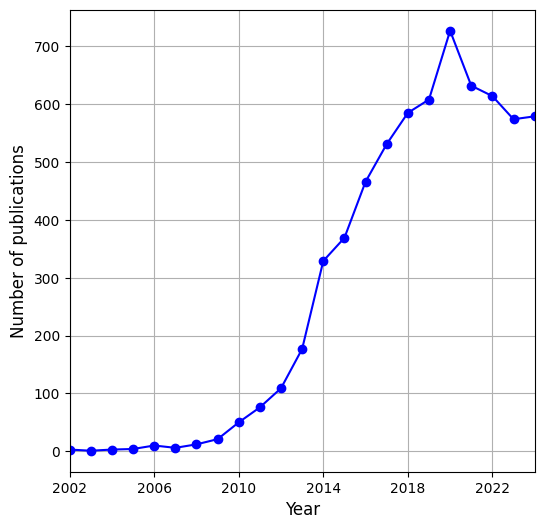

In [27]:
publication_years = data['insert_date'].astype(str).str.extract(r'^(\d{4})').astype(int).values
publication_years = pd.DataFrame(publication_years[publication_years < 2025])
publications_per_year = publication_years.value_counts().sort_index()

plt.figure(figsize=(6, 6))
plt.plot(publications_per_year.index.get_level_values(0), publications_per_year.values, marker='o', linestyle='-', color='b')

plt.xlabel('Year', fontsize=12)
plt.xlim([publication_years.min().values[0], publication_years.max().values[0]])
plt.xticks(range(publication_years.min().values[0], publication_years.max().values[0], 4))
plt.ylabel('Number of publications', fontsize=12)

plt.grid(True)

plt.savefig('../data/output/publications_per_year.pdf')

plt.show()

# Text preprocessing

In [28]:
# Concatenate abstract and index_terms

df = data[text_cols].copy()
df['text'] = df['abstract'] + ' ' + df['abstract'] + ' ' + df['index_terms']
df.head()

,title,index_terms,abstract,text
0,2n 1 selective harmonic elimination pwm for m...,switches harmonic analysis pulse width modulat...,the performance of modular multilevel converte...,the performance of modular multilevel converte...
1,beta ga2o3 in power electronics converters op...,schottky diodes costs performance evaluation d...,in this work the possibility of using differen...,in this work the possibility of using differen...
2,front cover,,the following topics are dealt with power semi...,the following topics are dealt with power semi...
3,1 5 kv 1 5 kw high voltage ratio bidirectional...,multilevel converters vacuum systems moon elem...,modular multilevel gan based isolated dc dc co...,modular multilevel gan based isolated dc dc co...
4,1 kv input 1 mhz gan modular multilevel llc co...,silicon carbide inductors hemts modfets stress...,a modular multilevel llc converter suitable fo...,a modular multilevel llc converter suitable fo...


In [29]:
# Apply text preprocessing
words2remove = []
df['text'] = df['text'].apply(lambda x: preprocess_text(x, words2remove))
df.head()

,title,index_terms,abstract,text
0,2n 1 selective harmonic elimination pwm for m...,switches harmonic analysis pulse width modulat...,the performance of modular multilevel converte...,performance modular multilevel converter mmcs ...
1,beta ga2o3 in power electronics converters op...,schottky diodes costs performance evaluation d...,in this work the possibility of using differen...,work possibility using different generation be...
2,front cover,,the following topics are dealt with power semi...,following topic dealt power semiconductor devi...
3,1 5 kv 1 5 kw high voltage ratio bidirectional...,multilevel converters vacuum systems moon elem...,modular multilevel gan based isolated dc dc co...,modular multilevel gan based isolated dc dc co...
4,1 kv input 1 mhz gan modular multilevel llc co...,silicon carbide inductors hemts modfets stress...,a modular multilevel llc converter suitable fo...,modular multilevel llc converter suitable high...


In [30]:
# Save df
save_data = True
if save_data:
    df.to_csv('../data/input/api/data_cleaned.csv', index=False)

# Word cloud

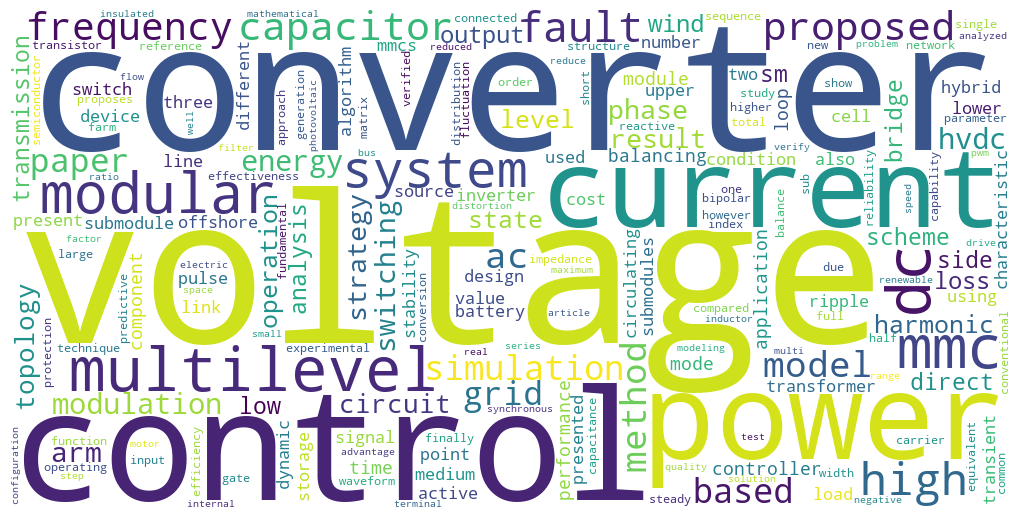

In [31]:
all_words = ' '.join(df['text'].str.split(' ').explode())
word_cloud(all_words)

# Vectorization

Tf idf

In [32]:
df_vectorized = df.copy()

In [33]:
vectorizer = TfidfVectorizer(ngram_range=(1, 1))
X_vectorized = vectorizer.fit_transform(df['text'])
words = vectorizer.get_feature_names_out()
df_vectorized = pd.DataFrame(X_vectorized.toarray(), columns=words)

# Save vectorizer
joblib.dump(vectorizer, '../models/vectorizer.pkl')

['../models/vectorizer.pkl']

In [34]:
vocabulary = ' '.join(df['text']).split(' ')

In [35]:
df_vectorized.columns

Index(['aa', 'aaac', 'aaar', 'aac', 'aachen', 'aacs', 'aam', 'aamc', 'aamcs',
       'aammc',
       ...
       'zscc', 'zss', 'zsv', 'zsvc', 'zsvi', 'zt', 'zurich', 'zvrt', 'zvs',
       'zynq'],
      dtype='object', length=11707)

In [36]:
len(words), len(vocabulary)

(11707, 1972591)

In [37]:
len(set(words)), len(set(vocabulary))

(11707, 11730)

In [38]:
len(set(words) - set(vocabulary))

0

In [39]:
len(set(vocabulary) - set(words))
set(vocabulary) - set(words)

{'b',
 'c',
 'd',
 'e',
 'f',
 'g',
 'h',
 'j',
 'k',
 'l',
 'm',
 'n',
 'o',
 'p',
 'q',
 'r',
 's',
 't',
 'u',
 'v',
 'w',
 'x',
 'z'}

In [40]:
# Vocabulary sorted by Tfidf score
df_vectorized.sum().sort_values()

lorentz         0.030143
ball            0.035428
coulombic       0.037850
aggressive      0.037850
schema          0.037998
                 ...    
current       370.756380
power         390.404655
control       463.403754
converter     465.070417
voltage       640.386945
Length: 11707, dtype: float64

In [41]:
# Vocabulary sorted by occurrence frequency
(df_vectorized != 0).sum().sort_values()

infrequent         1
playground         1
platformless       1
plated             1
drawer             1
                ... 
current         5884
voltage         6405
converter       6614
multilevel      6614
modular         6614
Length: 11707, dtype: int64

In [42]:
# Save df_vectorized
save_data = True
if save_data:
    df_vectorized.to_csv('../data/output/df_vectorized.csv', index=False)